# Spotting Spotify’s next Top 50 songs

**IS 4487 Business Analytics · Team case study**

**Team members**  
Jake Haskins, Flynn McConneloug, Victor Vazquez, Yewon Jeon

**Presentation video**  
*Link pending. Replace this line with the viewable video link before submitting.*

We test whether Spotify’s music editors could improve a five-track weekly review list by using chart movement and stream counts. Each prediction asks whether a track currently ranked 51–200 will reach the global Top 50 within the next four weeks.

Open this notebook in Google Colab or Jupyter and use **Run all**. The data cell downloads a pinned ZIP of public chart exports (about 10 MB). The notebook uses pandas, NumPy, Matplotlib and scikit-learn.

Verified with Python 3.12.13, pandas 3.1.1, NumPy 2.5.5, scikit-learn 1.9.1 and Matplotlib 3.11.2.

## CRISP-DM 1 · Business understanding

### Organization

Spotify is an audio streaming service. Its music editors curate playlists that help listeners discover songs and artists.

### Business challenge and impact

In September 2026 it expanded its support for early-career independent artists through Fresh Finds Forward. The business question here is narrower. Once a track starts drawing enough streams to chart globally, how should editors decide which five tracks to review for possible wider playlist placement? A stronger shortlist would surface more tracks with growing demand using the same amount of review time. [Spotify Newsroom, *Introducing Fresh Finds Forward*](https://newsroom.spotify.com/2026-09-17/fresh-finds-forward/)

### Industry context

The wider streaming market is growing and listener tastes shift. IFPI reports that paid subscription streaming revenue grew 8.8% in 2025. Associated Press reporting on Luminate’s 2026 midyear analysis describes faster global streaming growth and changes in the U.S. genre mix. These are reasons to check whether a rule learned from historical listening still holds in newer weeks. [IFPI, *Global Music Report 2026*](https://www.ifpi.org/global-music-report-2026-global-recorded-music-revenues-grow-6.4-as-record-companies-drive-innovation/) · [Associated Press, *Latin and country music streams surge in the US*](https://apnews.com/article/streaming-music-tv-netflix-luminate-midyear-4516213bc46fdafb557ffe645c086edf)

**Success criterion.** At the same review capacity of five tracks per week, surface more tracks that reach the Top 50 than the simple rule of choosing ranks 51–55. Five is a proposed review budget for this case study. The chart outcome measures demand for tracks already on the Top 200 and serves as a proxy for momentum. The data cannot identify Fresh Finds participants or measure what would happen after a playlist placement.

## CRISP-DM 2 · Data understanding

### Public data sources considered

| Dataset | Available information and role |
|---|---|
| [Spotify Global Weekly Top Songs](https://charts.spotify.com/charts/view/regional-global-weekly/latest) | **Primary.** Weekly chart rank, track ID, artist, title, chart-eligible streams and weeks on chart. We use 107 original CSV exports from a [pinned download mirror](https://github.com/evadatadev/musiktrends-spotify/tree/63d0741445ed9b8f725ab5760ee5273f1140d30a/data/raw). The chart directly measures our outcome. [Spotify’s chart methodology](https://support.spotify.com/us/artists/article/understanding-spotify-charts/) |
| [YouTube Global Weekly Top Songs](https://charts.youtube.com/charts/TopSongs/global/weekly) | **Candidate for future enrichment.** Ranks songs using YouTube views. This could show momentum outside Spotify after checking track matches and reporting dates. [YouTube chart methodology](https://support.google.com/youtube/answer/9014376) |
| [MusicBrainz database](https://musicbrainz.org/doc/MusicBrainz_Database/Download) | **Candidate for future enrichment.** Recording and release metadata could distinguish recent releases from older tracks that return to the chart. A match would require verified recording IDs. |

### 1. Import data tools

Use standard Python tools to open the archive, pandas for tables, NumPy for calculations and Matplotlib for the final figures.

In [1]:
import io
import re
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

### 2. Set the study rules

We set the chart range, forecast window, review budget and first test week before fitting models.

In [2]:
revision = "63d0741445ed9b8f725ab5760ee5273f1140d30a"
archive_url = f"https://codeload.github.com/evadatadev/musiktrends-spotify/zip/{revision}"
export_pattern = re.compile(r"/data/raw/(?:weekly-top-songs-global-20\d{2}/)?"
                            r"regional-global-weekly-(\d{4}-\d{2}-\d{2})(?:_origin)?\.csv$")
top_rank, last_rank = 50, 200
horizon, review_budget = 4, 5
week = pd.Timedelta(weeks=1)
test_start = pd.Timestamp("2025-07-03")
print(f"Score ranks {top_rank + 1}–{last_rank}, then look ahead {horizon} weeks.")

Score ranks 51–200, then look ahead 4 weeks.


### 3. Fetch the chart exports

Open the ZIP in memory and identify the raw weekly chart files by their names. The date in the file name is the chart week’s end date.

In [3]:
with urlopen(archive_url, timeout=90) as response:
    archive_bytes = response.read()

with ZipFile(io.BytesIO(archive_bytes)) as archive:
    exports = [name for name in sorted(archive.namelist()) if export_pattern.search(name)]
print(f"Found {len(exports)} weekly chart CSVs.")
print(exports[0].rsplit("/", 1)[-1])

Found 107 weekly chart CSVs.
regional-global-weekly-2026-01-08_origin.csv


### 4. Stack the weekly files

Read the same six columns from each CSV. Add the chart week and stack the files into one table.

In [4]:
fields = ["uri", "track_name", "artist_names", "rank", "streams", "weeks_on_chart"]
weekly_tables = []
with ZipFile(io.BytesIO(archive_bytes)) as archive:
    for filename in exports:
        with archive.open(filename) as csv_file:
            chart_week = pd.read_csv(csv_file, usecols=fields, encoding="utf-8-sig")
        chart_week["week"] = pd.Timestamp(export_pattern.search(filename)[1])
        weekly_tables.append(chart_week)
raw_chart = pd.concat(weekly_tables, ignore_index=True).sort_values(["week", "rank"])
display(raw_chart.head(3))

,rank,uri,artist_names,track_name,weeks_on_chart,streams,week
400,1,spotify:track:3rUGC1vUpkDG9CZFHMur1t,Tate McRae,greedy,16,33855816,2024-01-04
401,2,spotify:track:0R6NfOiLzLj4O5VbYSJAjf,Xavi,La Diabla,4,30894083,2024-01-04
402,3,spotify:track:4xhsWYTOGcal8zt0J161CU,Jack Harlow,Lovin On Me,8,30778444,2024-01-04


### 5. Inspect coverage and formats

Check the size, span and column types. The same track can appear in many weeks, so a row represents one track-week.

In [5]:
print(f"Rows: {len(raw_chart):,}. Weeks: {raw_chart['week'].nunique()}.")
print(f"From {raw_chart['week'].min():%Y-%m-%d} through {raw_chart['week'].max():%Y-%m-%d}.")
display(raw_chart.dtypes.rename("Data type").to_frame())

Rows: 21,399. Weeks: 107.
From 2024-01-04 through 2026-01-15.


,Data type
rank,int64
uri,str
artist_names,str
track_name,str
weeks_on_chart,int64
streams,int64
week,datetime64[us]


### 6. Check missing values and duplicate rows

A blank rank, stream count or track ID would affect our features or labels. Exact duplicate rows can be removed, while two conflicting records for the same track and week would need investigation.

In [6]:
display(raw_chart.isna().sum().rename("Missing values").to_frame())
print(f"Exact duplicate rows: {raw_chart.duplicated().sum()}")
print(f"Repeated track-week keys: {raw_chart.duplicated(['week', 'uri']).sum()}")

,Missing values
rank,0
uri,0
artist_names,0
track_name,0
weeks_on_chart,0
streams,0
week,0


Exact duplicate rows: 0
Repeated track-week keys: 0


### 7. Inspect the numeric ranges

Compare the median and upper percentiles with the maximum. Real hit songs can have unusually high streams, so we retain valid extremes and use log transforms for skewed measures. Figure 1 shows how the chart cutoff moves over time.

In [7]:
numeric_fields = ["rank", "streams", "weeks_on_chart"]
summary = raw_chart[numeric_fields].describe(percentiles=[.25, .5, .75, .95, .99])
display(summary.round(1))

,rank,streams,weeks_on_chart
count,21399.0,21399.0,21399.0
mean,100.5,13646292.1,59.2
std,57.7,7853851.9,74.4
min,1.0,7711230.0,1.0
25%,50.5,9434468.5,9.0
50%,101.0,10998405.0,30.0
75%,150.5,14631503.0,81.0
95%,190.1,27564197.0,217.0
99%,198.0,49764485.5,359.0
max,200.0,128896137.0,430.0


### 8. Plot the distribution of chart streams

The long right tail shows why we use log streams in the models. This plot covers all chart positions and shows how far the highest stream counts are from the typical track. The final presentation figures are grouped in the evaluation section.

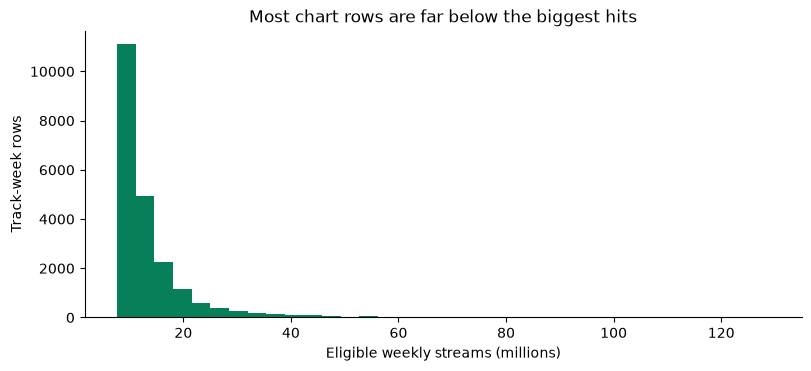

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
ax.hist(raw_chart["streams"] / 1_000_000, bins=35, color="#087F5B")
ax.set(title="Most chart rows are far below the biggest hits",
       xlabel="Eligible weekly streams (millions)", ylabel="Track-week rows")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## CRISP-DM 3 · Data preparation

### 9. Clean and verify weekly keys

Remove exact duplicates, strip the URI prefix and check that each week has a unique rank and track ID per row. Ranks outside 1–200 or invalid stream counts would stop the analysis so we can check the source.

In [9]:
chart = raw_chart.drop_duplicates().copy()
chart["track_id"] = chart.pop("uri").str.removeprefix("spotify:track:")
assert chart.notna().all().all(), "Unexpected missing value. Check the raw export."
assert chart["track_id"].str.fullmatch(r"[A-Za-z0-9]{22}").all()
assert not chart.duplicated(["week", "track_id"]).any()
assert not chart.duplicated(["week", "rank"]).any()
assert chart["rank"].between(1, last_rank).all()
assert chart["streams"].gt(0).all() and chart["weeks_on_chart"].ge(1).all()
print(f"Verified {len(chart):,} chart rows with unique track-week and rank-week keys.")

Verified 21,399 chart rows with unique track-week and rank-week keys.


### 10. Check complete charts and Top 50 coverage

We need all 200 ranks for fair scoring and prior-week features. To label later outcomes, a complete Top 50 is sufficient. The incomplete November 13 chart lacks rank 74, so it can still support labels.

In [10]:
ranks_by_week = chart.groupby("week")["rank"].agg(set)
expected_weeks = pd.date_range(ranks_by_week.index.min(), ranks_by_week.index.max(), freq="W-THU")
assert ranks_by_week.index.equals(expected_weeks), "A chart date is missing."
full_ranks = set(range(1, last_rank + 1))
complete_chart = ranks_by_week.map(lambda ranks: ranks == full_ranks)
assert ranks_by_week.map(set(range(1, top_rank + 1)).issubset).all()
for date, ranks in ranks_by_week[~complete_chart].items():
    print(f"{date:%Y-%m-%d} is missing ranks {sorted(full_ranks - ranks)}.")
print("Every weekly Top 50 is complete.")

2025-11-13 is missing ranks [74].
Every weekly Top 50 is complete.


### 11. Link each candidate to the prior week

Use the track ID and exact previous chart week. A missing prior rank here means the recording was outside that week’s Top 200, once incomplete charts have been excluded.

In [11]:
prior = chart[["week", "track_id", "rank", "streams"]].rename(
    columns={"rank": "prior_rank", "streams": "prior_streams"})
prior["week"] += week
candidates = chart.loc[chart["rank"].gt(top_rank)].merge(
    prior, on=["week", "track_id"], how="left", validate="one_to_one")
display(candidates[["week", "rank", "prior_rank", "streams", "prior_streams"]].head(3))

,week,rank,prior_rank,streams,prior_streams
0,2024-01-04,51,NaN,12929770,NaN
1,2024-01-04,52,NaN,12524320,NaN
2,2024-01-04,53,NaN,12505037,NaN


### 12. Keep weeks with enough history and follow-up

Exclude the first week, weeks with incomplete current or prior charts, and the last four weeks. This leaves a complete shortlist pool and four observed outcome weeks for every row.

In [12]:
current_complete = candidates["week"].isin(complete_chart[complete_chart].index)
prior_complete = (candidates["week"] - week).isin(complete_chart[complete_chart].index)
has_followup = candidates["week"].le(expected_weeks.max() - horizon * week)
candidates = candidates.loc[current_complete & prior_complete & has_followup].copy()
assert candidates.groupby("week").size().eq(last_rank - top_rank).all()
print(f"{len(candidates):,} eligible track-week rows before the time split.")

15,000 eligible track-week rows before the time split.


### 13. Measure proximity to the cutoff

Current rank is the baseline signal. Take logs of streams and weeks on chart to reduce skew. Subtract the log of the week’s rank-50 streams to measure proximity on a scale that accounts for the week’s chart threshold.

In [13]:
cutoff_streams = chart.loc[chart["rank"].eq(top_rank)].set_index("week")["streams"]
candidates["log_streams"] = np.log(candidates["streams"])
candidates["log_streams_vs_rank_50"] = (
    candidates["log_streams"] - np.log(candidates["week"].map(cutoff_streams)))
candidates["log_weeks_on_chart"] = np.log1p(candidates["weeks_on_chart"])
display(candidates[["rank", "log_streams", "log_streams_vs_rank_50", "log_weeks_on_chart"]].head(3))

,rank,log_streams,log_streams_vs_rank_50,log_weeks_on_chart
150,51,16.382044,-0.007768,2.484907
151,52,16.381813,-0.007999,2.639057
152,53,16.374277,-0.015535,3.178054


### 14. Calculate rank and stream movement

Encode prior-week chart appearance as 1 or 0. If a song was outside that Top 200, set its two undefined changes to zero and let the appearance flag distinguish those cases from genuine zero changes. A positive change means an improvement.

In [14]:
candidates["was_on_chart_last_week"] = candidates["prior_rank"].notna().astype(int)
candidates["rank_change"] = (candidates["prior_rank"] - candidates["rank"]).fillna(0)
candidates["log_stream_change"] = (
    candidates["log_streams"] - np.log(candidates["prior_streams"])).fillna(0)
movement = ["was_on_chart_last_week", "rank_change", "log_stream_change"]
display(candidates[["rank", "prior_rank"] + movement].head(3))

,rank,prior_rank,was_on_chart_last_week,rank_change,log_stream_change
150,51,52.0,1,1.0,0.038861
151,52,81.0,1,29.0,0.219394
152,53,47.0,1,-6.0,-0.028774


### 15. Label the four-week outcome

Check the track ID against the Top 50 in each of the next four charts. One match makes the outcome 1, even if the track disappears from the chart and returns during the window.

In [15]:
top_50 = pd.MultiIndex.from_frame(chart.loc[chart["rank"].le(top_rank), ["week", "track_id"]])
hits = np.zeros(len(candidates), dtype=bool)
for offset in range(1, horizon + 1):
    future_keys = pd.MultiIndex.from_arrays([candidates["week"] + offset * week, candidates["track_id"]])
    hits |= future_keys.isin(top_50)
candidates["hit"] = hits.astype(int)
display(candidates[["week", "rank", "track_name", "hit"]].head(5))

,week,rank,track_name,hit
150,2024-01-11,51,Is It Over Now? (Taylor's Version) (From The V...,0
151,2024-01-11,52,Rich Baby Daddy (feat. Sexyy Red & SZA),1
152,2024-01-11,53,EL AMOR DE SU VIDA,0
153,2024-01-11,54,Another Love,0
154,2024-01-11,55,See You Again (feat. Kali Uchis),0


### 16. Choose the seven model inputs

Keep only chart fields available when the shortlist is made. Titles, track IDs and artist names identify the picks. We exclude them from training, so there are no nominal text categories to encode. The binary prior-chart flag is the only categorical input.

In [16]:
feature_columns = ["rank", "log_streams", "log_streams_vs_rank_50", "log_weeks_on_chart",
                   "was_on_chart_last_week", "rank_change", "log_stream_change"]
assert len(feature_columns) == 7
assert np.isfinite(candidates[feature_columns].to_numpy()).all()
display(candidates[feature_columns].describe().round(2).T)

,count,mean,std,min,25%,50%,75%,max
rank,15000.0,125.50,43.30,51.00,88.00,125.50,163.00,200.00
log_streams,15000.0,16.16,0.16,15.86,16.03,16.13,16.27,16.88
log_streams_vs_rank_50,15000.0,-0.35,0.16,-0.84,-0.47,-0.37,-0.24,-0.00
log_weeks_on_chart,15000.0,3.44,1.40,0.69,2.40,3.61,4.55,6.06
was_on_chart_last_week,15000.0,0.88,0.33,0.00,1.00,1.00,1.00,1.00
rank_change,15000.0,-4.42,23.01,-176.00,-14.00,-2.00,5.00,143.00
log_stream_change,15000.0,-0.02,0.09,-2.27,-0.04,-0.01,0.01,0.75


### 17. Separate development and final test weeks

Development includes only rows with outcomes known before July 3, 2025. Four scoring weeks are left out between the two samples so development labels never extend into the test. The test set stays out of tuning.

In [17]:
label_end = candidates["week"] + horizon * week
development = candidates.loc[label_end.lt(test_start)].copy()
test = candidates.loc[candidates["week"].ge(test_start)].copy()
assert development["week"].max() + horizon * week < test["week"].min()
for name, data in [("Development", development), ("Held-out test", test)]:
    first, last = data["week"].min().date(), data["week"].max().date()
    print(f"{name}: {len(data):,} rows, {data['week'].nunique()} weeks, {first} to {last}.")
print(f"Gap rows held out: {len(candidates) - len(development) - len(test):,}")

Development: 10,950 rows, 73 weeks, 2024-01-11 to 2025-05-29.
Held-out test: 3,450 rows, 23 weeks, 2025-07-03 to 2025-12-18.
Gap rows held out: 600


### 18. Explore outcomes in the development set

Check how often tracks reach the Top 50 and whether the starting-rank groups differ. We use development outcomes for exploration while keeping test results for the final comparison. Figures 2 and 3 visualize development outcomes.

In [18]:
rank_edges = [50, 75, 100, 150, 200]
rank_labels = ["51–75", "76–100", "101–150", "151–200"]
development["rank_band"] = pd.cut(development["rank"], rank_edges, labels=rank_labels)
rank_outcomes = development.groupby("rank_band", observed=True)["hit"].agg(["size", "sum", "mean"])
print(f"Overall development hit rate: {development['hit'].mean():.1%}")
display(rank_outcomes.rename(columns={"size": "Candidates", "sum": "Hits", "mean": "Hit rate"}).round(3))

Overall development hit rate: 6.5%


,Candidates,Hits,Hit rate
rank_band,,,
51–75,1825,432,0.237
76–100,1825,138,0.076
101–150,3650,99,0.027
151–200,3650,47,0.013


## CRISP-DM 4 · Modeling

We use two classifiers from class. **Logistic regression** is a straightforward starting point for a yes/no outcome. It uses standardized inputs and adjusts the amount of regularization through `C`. **Random forest** can use interactions, such as a rapid change in streams mattering differently at different ranks. We limit tree depth and leaf size to control complexity. The **current-rank rule** is a comparison baseline.

### 19. Load the classroom models and validation tools

We use scikit-learn. A pipeline fits the scaler inside each training fold so its averages and standard deviations come from past data.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

### 20. Group validation by chart week

Use three ten-week validation periods. Each starts after a four-week gap in scoring dates. All tracks from a week stay together, which preserves the shortlist decision and prevents random row splitting from mixing past and future.

In [20]:
train_x = development.set_index("week")[feature_columns]
train_y = development.set_index("week")["hit"]
earlier_weeks = train_x.index.unique().sort_values()
splitter = TimeSeriesSplit(n_splits=3, test_size=10, gap=horizon)
folds = []
for past, later in splitter.split(earlier_weeks):
    past_rows = np.flatnonzero(train_x.index.isin(earlier_weeks[past]))
    later_rows = np.flatnonzero(train_x.index.isin(earlier_weeks[later]))
    folds.append((past_rows, later_rows))

### 21. Confirm the timing of every fold

The last training outcome date must precede the first validation scoring date. The fold output lets us check this directly.

In [21]:
for fold, (past_rows, later_rows) in enumerate(folds, start=1):
    last_past = train_x.index[past_rows].max()
    first_later, last_later = train_x.index[later_rows].min(), train_x.index[later_rows].max()
    assert last_past + horizon * week < first_later
    print(f"Fold {fold}: training ends {last_past:%Y-%m-%d}; "
          f"validation runs {first_later:%Y-%m-%d} to {last_later:%Y-%m-%d}.")

Fold 1: training ends 2024-10-03; validation runs 2024-11-07 to 2025-01-09.
Fold 2: training ends 2024-12-12; validation runs 2025-01-16 to 2025-03-20.
Fold 3: training ends 2025-02-20; validation runs 2025-03-27 to 2025-05-29.


### 22. Define how to count a correct pick

Sort by model score within a week and break ties using current rank. Precision at five is the share of the five picks that enter the Top 50. We use the same metric for tuning and the final holdout.

In [22]:
def weekly_picks(scored):
    ordered = scored.sort_values(["week", "score", "rank"], ascending=[True, False, True])
    return ordered.groupby("week", sort=False).head(review_budget)

def validation_precision(estimator, features, target):
    scored = features[["rank"]].reset_index().assign(
        score=estimator.predict_proba(features)[:, 1], hit=target.to_numpy())
    return weekly_picks(scored)["hit"].mean()

### 23. Tune logistic regression

Try four regularization strengths. Smaller `C` penalizes large coefficients more strongly. Select the setting with the highest mean validation precision at five and refit on all development weeks.

In [23]:
logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logistic_search = GridSearchCV(logistic, {"logisticregression__C": [.01, .1, 1, 10]},
                               scoring=validation_precision, cv=folds, error_score="raise")
logistic_search.fit(train_x, train_y)
logistic_scores = pd.DataFrame(logistic_search.cv_results_)
display(logistic_scores[["param_logisticregression__C", "mean_test_score"]].round(3))
print(f"Selected C: {logistic_search.best_params_['logisticregression__C']}")

,param_logisticregression__C,mean_test_score
0,0.01,0.467
1,0.10,0.493
2,1.00,0.513
3,10.00,0.513


Selected C: 1


### 24. Tune random forest

Try nine combinations of tree depth and minimum observations per leaf. Keep the number of trees fixed at 150 so the comparison focuses on tree complexity. Select by the same validation score and refit on all development weeks.

In [24]:
forest = RandomForestClassifier(n_estimators=150, random_state=4487, n_jobs=-1)
forest_grid = {"max_depth": [4, 8, 12], "min_samples_leaf": [8, 20, 40]}
forest_search = GridSearchCV(forest, forest_grid, scoring=validation_precision,
                             cv=folds, error_score="raise")
forest_search.fit(train_x, train_y)
forest_scores = pd.DataFrame(forest_search.cv_results_)
display(forest_scores[["param_max_depth", "param_min_samples_leaf", "mean_test_score"]].round(3))
print(f"Selected forest settings: {forest_search.best_params_}")

,param_max_depth,param_min_samples_leaf,mean_test_score
0,4,8,0.547
1,4,20,0.573
2,4,40,0.553
3,8,8,0.560
4,8,20,0.533
5,8,40,0.553
6,12,8,0.560
7,12,20,0.540
8,12,40,0.580


Selected forest settings: {'max_depth': 12, 'min_samples_leaf': 40}


## CRISP-DM 5 · Evaluation

Score the held-out weeks once with the selected settings. Precision at five answers the review-budget question. Average precision describes how well each approach ranks hits across the entire test pool, which could matter if editors eventually increase the review budget.

### 25. Score the held-out tracks

Use the refitted estimators for probabilities and negative rank for the baseline, so rank 51 always sorts first under the baseline.

In [25]:
scores = {"Current rank": -test["rank"].to_numpy(),
          "Logistic regression": logistic_search.predict_proba(test[feature_columns])[:, 1],
          "Random forest": forest_search.predict_proba(test[feature_columns])[:, 1]}
print(f"Scored {len(test):,} candidates with each approach.")
print(f"Held-out hits across all candidates: {test['hit'].sum():,} ({test['hit'].mean():.1%}).")

Scored 3,450 candidates with each approach.
Held-out hits across all candidates: 282 (8.2%).


### 26. Assemble three five-track shortlists

Apply the exact same review limit and tie-breaking to all three methods. Keep the candidate’s rank and outcome so we can show specific examples.

In [26]:
picks = {method: weekly_picks(test.assign(score=score)) for method, score in scores.items()}
for method, rows in picks.items():
    assert rows.groupby("week").size().eq(review_budget).all()
    print(f"{method}: {len(rows)} reviewed across {rows['week'].nunique()} weeks.")

Current rank: 115 reviewed across 23 weeks.
Logistic regression: 115 reviewed across 23 weeks.
Random forest: 115 reviewed across 23 weeks.


### 27. Compare the test results side by side

Use correct picks and their share at the five-track review limit. Average precision is calculated on all scored rows. A better full ranking can still yield the same number of correct picks at five.

In [27]:
comparison = pd.DataFrame({method: {
    "Correct picks": int(rows["hit"].sum()), "Total picks": len(rows),
    "Precision at 5": rows["hit"].mean(),
    "Average precision": average_precision_score(test["hit"], scores[method]),
} for method, rows in picks.items()}).T
comparison[["Correct picks", "Total picks"]] = comparison[["Correct picks", "Total picks"]].astype(int)
display(comparison.round(3))

,Correct picks,Total picks,Precision at 5,Average precision
Current rank,55,115,0.478,0.313
Logistic regression,55,115,0.478,0.425
Random forest,59,115,0.513,0.434


### 28. Check week-to-week consistency

Compare each model’s number of correct picks with the baseline per week. Four-week outcomes overlap and songs can recur, so these comparisons describe the test period.

In [28]:
weekly_hits = pd.DataFrame({method: rows.groupby("week")["hit"].sum() for method, rows in picks.items()})
for method in ["Logistic regression", "Random forest"]:
    difference = weekly_hits[method] - weekly_hits["Current rank"]
    print(f"{method}: {(difference > 0).sum()} better weeks, {(difference == 0).sum()} ties, "
          f"and {(difference < 0).sum()} worse weeks versus current rank.")

Logistic regression: 5 better weeks, 13 ties, and 5 worse weeks versus current rank.
Random forest: 7 better weeks, 13 ties, and 3 worse weeks versus current rank.


### 29. Look at one example review week

October 2 illustrates which songs the baseline and forest would send to editors. A hit in this table means the song later charted in the Top 50 within four weeks.

In [29]:
example_week = pd.Timestamp("2025-10-02")
example_fields = ["rank", "track_name", "artist_names", "hit"]
example = pd.concat({method: rows.loc[rows["week"].eq(example_week), example_fields]
                     for method, rows in picks.items() if method in ["Current rank", "Random forest"]})
example = example.reset_index(level=0, names="Method").reset_index(drop=True)
display(example.replace({"hit": {0: "No", 1: "Yes"}}).rename(columns={"hit": "Reached Top 50"}))

,Method,rank,track_name,artist_names,Reached Top 50
0,Current rank,51,Every Breath You Take,The Police,Yes
1,Current rank,52,no tiene sentido,Beéle,No
2,Current rank,53,Sahiba,Aditya Rikhari,No
3,Current rank,54,TU VAS SIN (fav),Rels B,No
4,Current rank,55,Espresso,Sabrina Carpenter,No
5,Random forest,51,Every Breath You Take,The Police,Yes
6,Random forest,59,Nice To Each Other,Olivia Dean,No
7,Random forest,52,no tiene sentido,Beéle,No
8,Random forest,53,Sahiba,Aditya Rikhari,No
9,Random forest,61,Qué Pasaría...,"Rauw Alejandro, Bad Bunny",No


### 30. Inspect the random forest’s input importance

This table describes how much each input contributed to reducing uncertainty at the forest’s splits. Rank and stream measures are related, so importance can be shared across them. The table helps explain the fitted forest. It does not show which signals cause hits or guarantee the same importance on newer weeks.

In [30]:
importance = pd.Series(forest_search.best_estimator_.feature_importances_, index=feature_columns)
importance = importance.sort_values(ascending=False).rename("Share of split improvement")
display(importance.round(3).to_frame())

,Share of split improvement
log_streams,0.361
log_streams_vs_rank_50,0.233
rank,0.184
log_stream_change,0.100
log_weeks_on_chart,0.066
rank_change,0.044
was_on_chart_last_week,0.012


### Six final charts for the presentation

Figures 1–3 explain the data and how candidate tracks differ. Figures 4–6 compare the forecasting approaches and show how weekly review results vary. The models use only predictors available when each chart is published.

### 31. Set shared chart formatting

Use the same colors for each method across the figures. The percentage scale starts at zero so small differences stay in proportion.

In [31]:
from matplotlib.ticker import PercentFormatter

methods = ["Current rank", "Logistic regression", "Random forest"]
colors = ["#60778A", "#087F5B", "#6646A3"]
plt.rcParams.update({"figure.figsize": (8.0, 3.6), "figure.dpi": 130,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.axisbelow": True,
                     "axes.grid": True, "grid.alpha": .22, "font.size": 10})

### 32. Figure 1 · Streams needed to reach rank 50

The threshold changes across the archive. The cutoff feature lets us describe how close a song is relative to its own week.

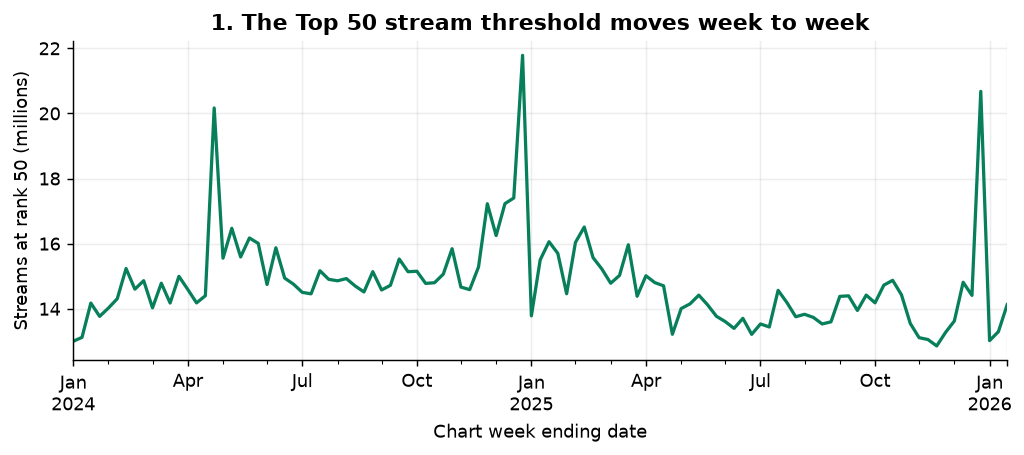

In [32]:
ax = cutoff_streams.div(1_000_000).plot(color=colors[1], linewidth=1.8)
ax.set(title="1. The Top 50 stream threshold moves week to week",
       xlabel="Chart week ending date", ylabel="Streams at rank 50 (millions)")
plt.tight_layout()
plt.show()

### 33. Figure 2 · Future hit rate by current rank

This development-set chart shows whether tracks near the cutoff are already more likely to reach the Top 50. The bars are rates within each rank band.

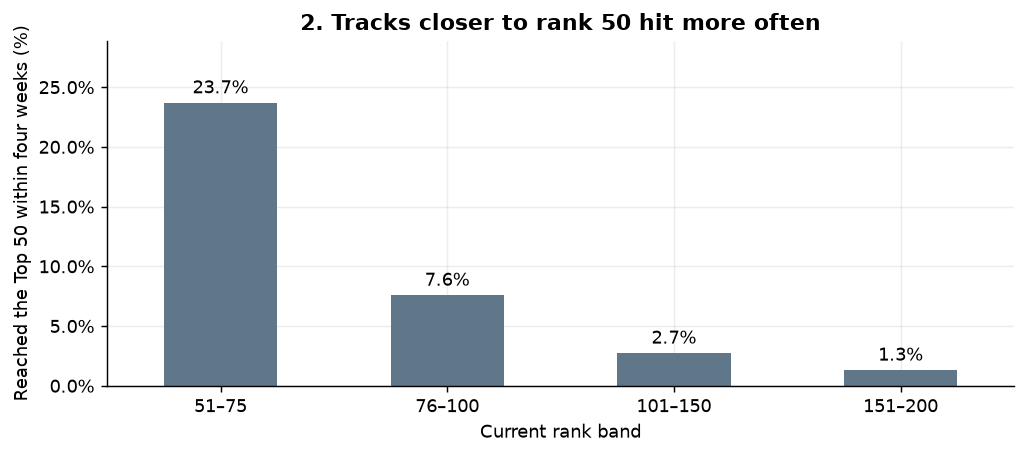

In [33]:
ax = rank_outcomes["mean"].plot.bar(color=colors[0], rot=0)
ax.set(title="2. Tracks closer to rank 50 hit more often", xlabel="Current rank band",
       ylabel="Reached the Top 50 within four weeks (%)")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.bar_label(ax.containers[0], labels=[f"{rate:.1%}" for rate in rank_outcomes["mean"]], padding=3)
ax.set_ylim(0, rank_outcomes["mean"].max() * 1.22)
plt.tight_layout()
plt.show()

### 34. Figure 3 · Future hit rate by stream momentum

Compare tracks with rising streams, tracks with flat or falling streams, and tracks outside the Top 200 one week earlier. The groups describe an association in the development set and do not isolate the effect of momentum.

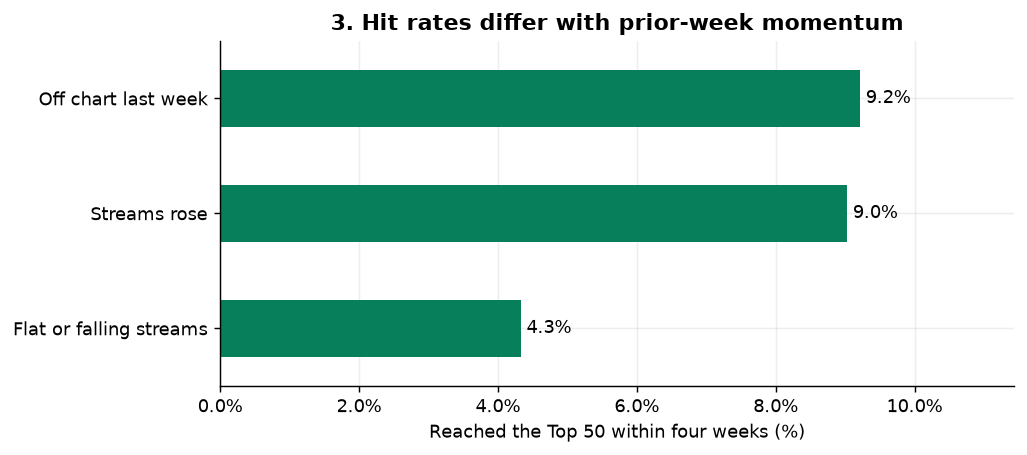

In [34]:
movement_group = np.select([development["was_on_chart_last_week"].eq(0), development["log_stream_change"].gt(0)],
                           ["Off chart last week", "Streams rose"], default="Flat or falling streams")
movement_rates = development.groupby(movement_group)["hit"].mean().sort_values()
ax = movement_rates.plot.barh(color=colors[1])
ax.set(title="3. Hit rates differ with prior-week momentum", xlabel="Reached the Top 50 within four weeks (%)")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.bar_label(ax.containers[0], labels=[f"{rate:.1%}" for rate in movement_rates], padding=3)
ax.set_xlim(0, movement_rates.max() * 1.24)
plt.tight_layout()
plt.show()

### 35. Figure 4 · Correct picks at the weekly review limit

This is the decision chart. Every method chose five tracks in each of the same 23 held-out weeks.

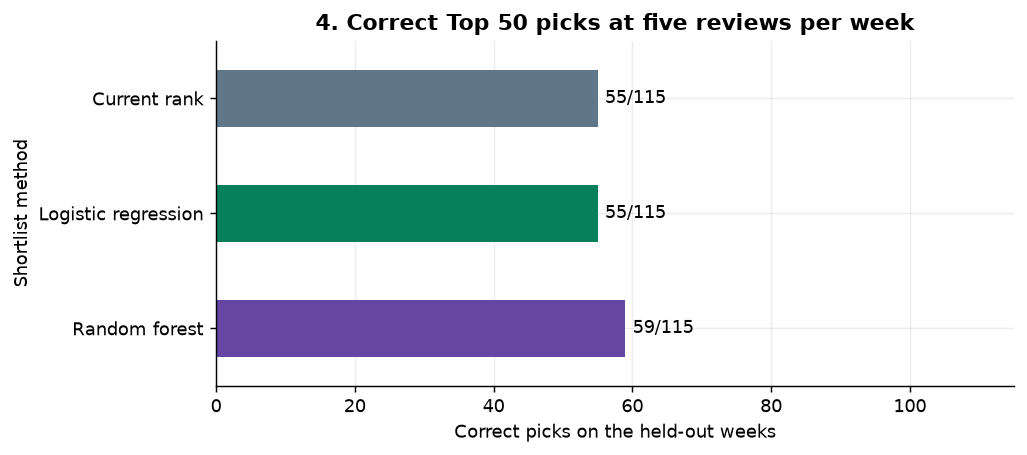

In [35]:
ax = comparison.loc[methods, "Correct picks"].plot.barh(color=colors)
total_picks = int(comparison["Total picks"].iloc[0])
labels = [f"{count}/{total_picks}" for count in comparison.loc[methods, "Correct picks"]]
ax.bar_label(ax.containers[0], labels=labels, padding=4)
ax.set(title="4. Correct Top 50 picks at five reviews per week", xlabel="Correct picks on the held-out weeks",
       ylabel="Shortlist method", xlim=(0, total_picks))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 36. Figure 5 · Average precision over all candidates

This view compares the rankings across all test candidates. A score closer to 1 means hits tended to appear sooner as more candidates were considered.

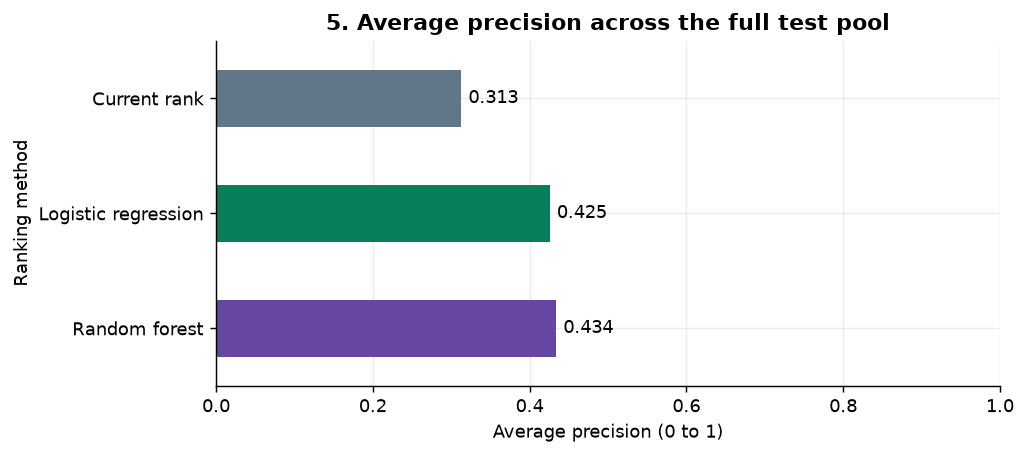

In [36]:
ax = comparison.loc[methods, "Average precision"].plot.barh(color=colors)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=4)
ax.set(title="5. Average precision across the full test pool", xlabel="Average precision (0 to 1)",
       ylabel="Ranking method", xlim=(0, 1))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 37. Figure 6 · Shortlist performance by month

Compare rates within months to see how consistent each method was. November contains fewer scoring weeks because of the incomplete chart. December ends on the last week with full outcome coverage.

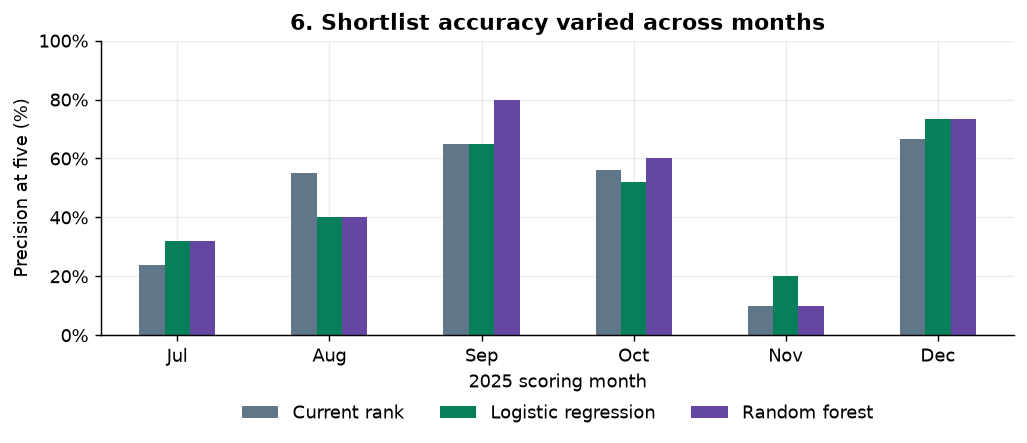

In [37]:
month = weekly_hits.index.to_period("M")
monthly_rate = weekly_hits.groupby(month).mean().div(review_budget)
ax = monthly_rate.rename(index=lambda value: value.strftime("%b")).plot.bar(color=colors, rot=0)
ax.set(title="6. Shortlist accuracy varied across months", xlabel="2025 scoring month",
       ylabel="Precision at five (%)", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -.18), ncol=3)
plt.tight_layout()
plt.show()

## CRISP-DM 6 · Deployment and recommendations

**Best fitted model.** The tuned random forest had the most correct picks on the test weeks, 59 of 115 (51.3%). Logistic regression and the current-rank rule each had 55 (47.8%). Both fitted models ranked the full pool better by average precision, with 0.434 for the forest, 0.425 for logistic regression and 0.313 for current rank. The forest beat current rank in seven weeks, tied in 13 and trailed in three.

**Recommendation.** Use current rank for routine five-track shortlists and test the forest alongside it on newer charts. Four additional correct picks over 23 weeks provide a reason to test the forest again. The gain varies by month, and the simple rule requires only the current chart. Logistic regression is easier to inspect and improved the full ranking, but it gave the same number of correct picks under the five-track limit.

**Proposed workflow.** The music editorial team can use each chart’s publication date as the weekly scoring cutoff. Keep the same five-review budget for the baseline and the tuned model. Score both lists in parallel for a proposed 12 new weeks while editors keep their usual playlist process. Record correct picks after four weeks and track how long editors spend reviewing them.

**Limits.** This is one historical holdout for tracks already charting globally. Repeated tracks and overlapping outcome windows make the results dependent across weeks. The charts measure eligible streams and do not include saves, listener satisfaction, playlist exposures or a recording’s independent-artist status. A later controlled pilot would be needed to measure whether placement changes listener outcomes.